In [100]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [101]:

tickers = [
    "SOXX", "IGV", "FDN", "IYZ", # Technology & Communications
    "IBB", "IHI", "IHF", "XPH",  # Health care
    "KRE", "KBE", "KIE", "IAI",  # Financials
    "XOP", "OIH",                # Energy
    "ITA", "IYT", "PHO",         # Industrials
    "XME", "GDX", "SLX",         # Materials
    "XRT", "XHB", "PEJ",         # Consumer Discretionary
    "XLP", "PBJ",                # Consumer Staples
    "IYR",                       # Real Estate
    "XLU",                       # Utilities
]

# data = yf.download(tickers, start="2006-01-01", auto_adjust=True, progress=False)["Close"]
# p = data[tickers].dropna(how="all")
# p.to_csv("./prices.csv")

# Market for beta calculation
sp = yf.download("^GSPC", start="2006-01-01", auto_adjust=True, progress=False)["Close"].squeeze()
sp_m = sp.groupby(sp.index.to_period("M")).tail(1)
sp_m.index = sp_m.index.to_period("M")

p = pd.read_csv("./prices.csv", index_col=0, parse_dates=True)

In [102]:
# month-end closes: the rebalance grid. The running month is dropped, it has no close yet.
month_end = p.groupby(p.index.to_period("M")).tail(1)
if month_end.index[-1] == p.index[-1]:
    month_end = month_end.iloc[:-1]
month_end.index = month_end.index.to_period("M")
ret = month_end.pct_change().dropna(how="any")

# raise if dropna created a time-skip
assert ret.index.equals(pd.period_range(ret.index[0], ret.index[-1], freq="M"))

ret.iloc[:5, :5]

,SOXX,IGV,FDN,IYZ,IBB
Date,,,,,
2006-11,0.032851,0.028048,0.037997,-0.006272,0.006536
2006-12,-0.029582,-0.019120,-0.027562,0.045207,-0.028959
2007-01,-0.003278,0.007851,0.049159,0.037100,0.026749
2007-02,0.017596,-0.016025,-0.012241,-0.004878,-0.032690
2007-03,-0.024507,0.019453,-0.003419,0.021886,-0.018775


In [128]:
bin = len(tickers) // 3

form = month_end.shift(1) / month_end.shift(12) - 1
rank = form.rank(axis=1, ascending=False)
w = ((rank <= bin).astype(float) - (rank > len(tickers) - bin).astype(float)) / bin
w = w.loc[form.notna().all(axis=1)]      # w at m is held over m+1

w.iloc[:5, :5]

,SOXX,IGV,FDN,IYZ,IBB
Date,,,,,
2007-10,0.000000,0.000000,0.000000,0.111111,0.0
2007-11,0.000000,0.000000,0.111111,0.000000,0.0
2007-12,-0.111111,0.000000,0.000000,0.000000,0.0
2008-01,0.000000,0.111111,0.000000,0.000000,0.0
2008-02,-0.111111,0.000000,0.000000,-0.111111,0.0


In [104]:
held = w.set_axis(w.index + 1).loc[:ret.index[-1]]   # weights labelled by the month they earn
turnover = w.diff().abs().sum(axis=1)
turnover.iloc[0] = w.iloc[0].abs().sum()             # entry: one unit long, one unit short
turnover = turnover.set_axis(w.index + 1).loc[held.index]
cost = turnover * (5/10000)

net = (held * ret).sum(axis=1).loc[held.index] - cost
eq = (1 + net).cumprod()

print(pd.Series({
    "Ann. return": eq.iloc[-1] ** (12 / len(net)) - 1,
    "Ann. vol": net.std() * 12 ** 0.5,
    "Sharpe": net.mean() / net.std() * 12 ** 0.5,
    "Worst month": net.min(),
    "Max drawdown": (eq / eq.cummax() - 1).min(),
    "Ann. turnover": turnover.mean() * 12,
    "Ann. cost": cost.mean() * 12,
}).round(4))

Ann. return     -0.0031
Ann. vol         0.1571
Sharpe           0.0589
Worst month     -0.1937
Max drawdown    -0.6140
Ann. turnover    8.8187
Ann. cost        0.0044
dtype: float64


In [125]:
mkt = sp_m.pct_change().reindex(held.index)

long_leg = (held.clip(lower=0) * ret).sum(axis=1).loc[held.index]
short_leg = (-held.clip(upper=0) * ret).sum(axis=1).loc[held.index]

print("Monthly betas: ")
for n, r in [("Long", long_leg), ("Short", short_leg), ("Net", net)]:
    beta = np.cov(r, mkt, ddof=1)[0, 1] / np.var(mkt, ddof=1)
    print(f"  {n}: {beta:.3f}")

Monthly betas: 
  Long: 1.033
  Short: 1.195
  Net: -0.162


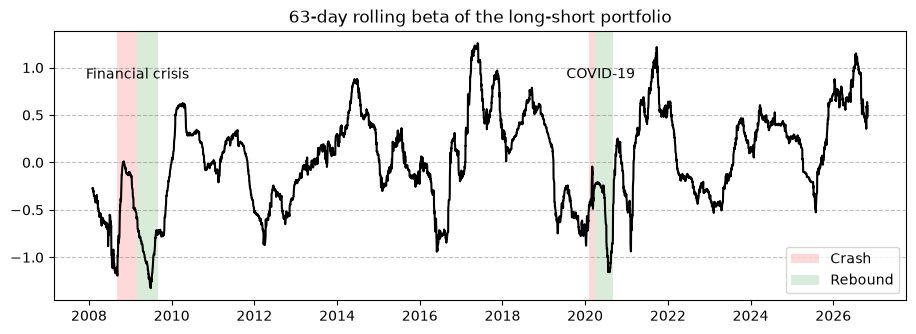

In [ ]:
# exposure on daily returns: a monthly window cannot resolve the 2008 or 2020 shock
dret = p.pct_change()
dret = dret[dret.index.to_period("M").isin(held.index)]
wd = held.reindex(dret.index.to_period("M")).set_axis(dret.index)
dmkt = sp.pct_change().reindex(dret.index).dropna()
dnet = (wd * dret).sum(axis=1)
dlong = (wd.clip(lower=0) * dret).sum(axis=1)
dshort = (-wd.clip(upper=0) * dret).sum(axis=1)

beta = dnet.rolling(63).cov(dmkt) / dmkt.rolling(63).var()

windows = {"Financial crisis": (("2008-09", "2009-02"), ("2009-03", "2009-08")),
           "COVID-19":         (("2020-02", "2020-03"), ("2020-04", "2020-08"))}

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(beta.index, beta, color="black")
ax.grid(axis="y", color="grey", linestyle="--", alpha=0.5)
for k, (c, r) in windows.items():
    annot_rng = dmkt[c[0]:r[1]]
    annot_mid = annot_rng.index[len(annot_rng) // 2]
    ax.annotate(k, xy=(annot_mid, 1.0), ha="center", va="top", fontsize=10, color="black")
    ax.axvspan(*dmkt[c[0]:c[1]].index[[0, -1]], color="red", alpha=0.15, lw=0)
    ax.axvspan(*dmkt[r[0]:r[1]].index[[0, -1]], color="green", alpha=0.15, lw=0)

ax.legend(handles=[
    Patch(facecolor="red", alpha=0.15, label="Crash"),
    Patch(facecolor="green", alpha=0.15, label="Rebound"),
], loc="lower right")
ax.set_title("63-day rolling beta of the long-short portfolio")
plt.show()


In [129]:
def beta_of(r, m):
    return np.cov(r.reindex(m.index), m)[0, 1] / np.var(m, ddof=1)

rows = {}
for k, phases in windows.items():
    for phase, (lo, hi) in zip(("Crash", "Rebound"), phases):
        m = dmkt[lo:hi]
        rows[k, phase] = {"Long": beta_of(dlong, m), "Short": beta_of(dshort, m),
                          "Net": beta_of(dnet, m), "Days": len(m)}

print("Daily betas by phase:")
print(pd.DataFrame(rows).T.round(2).astype({"Days": int}))

Daily betas by phase:
                          Long  Short   Net  Days
Financial crisis Crash    0.98   1.21 -0.23   124
                 Rebound  0.71   1.72 -1.00   128
COVID-19         Crash    0.91   1.14 -0.23    41
                 Rebound  0.90   1.48 -0.58   106
